In [135]:
import pandas as pd 
from sklearn.decomposition import PCA

# read the data 
df = pd.read_csv("data/gdsc_expr_postCB.csv")

# visualize the top 5 rows 
df.head(n=5)

# We see that the first column contains the name of the genes and the first row contains names/IDs of the samples 

,Unnamed: 0,906877,906798,906872,906873,906870,906871,906793,906792,906791,...,907317,907318,907319,1299059,684059,684052,684057,687807,684055,1322213
0,ENSG00000000003,2.508729,7.037164,2.577397,7.045888,4.543037,6.801862,5.300144,5.933979,6.911063,...,6.883014,7.880665,7.088381,7.437321,7.009003,6.127656,6.923300,6.758779,7.313623,4.855711
1,ENSG00000000419,8.968814,9.032526,8.567381,8.617857,7.873480,8.888909,8.892322,7.913833,7.615324,...,9.029970,9.084141,8.425315,7.433776,7.935236,8.072725,8.172654,7.131534,8.147621,8.349442
2,ENSG00000000457,4.432231,2.931877,2.560122,2.654424,3.753498,3.204206,3.757574,3.268314,3.680308,...,3.180330,2.901296,2.350121,3.739198,2.957672,3.114235,3.774264,2.935753,3.586686,2.808046
3,ENSG00000000460,3.887446,1.713152,2.167990,2.196951,2.760429,2.628319,2.443053,2.804103,3.997609,...,2.214473,1.844454,1.831997,2.325919,2.352136,2.605327,2.839715,3.004388,2.100455,2.297867
4,ENSG00000000938,2.575608,2.447280,2.777488,2.439445,2.762941,2.919733,2.570636,2.595269,2.643118,...,2.525579,2.739947,2.493749,2.523586,2.359968,2.377841,2.427464,2.811448,2.618779,2.584757


In [136]:
# The libraries we use for dimentionality reduction assume that rows are samples and columns are features which is not the case in transcriptomic data
# so let's transpose the dataframe
df = df.T
df.head(n=5)

,0,1,2,3,4,5,6,7,8,9,...,13931,13932,13933,13934,13935,13936,13937,13938,13939,13940
Unnamed: 0,ENSG00000000003,ENSG00000000419,ENSG00000000457,ENSG00000000460,ENSG00000000938,ENSG00000000971,ENSG00000001036,ENSG00000001084,ENSG00000001167,ENSG00000001460,...,ENSG00000261685,ENSG00000261701,ENSG00000261857,ENSG00000263002,ENSG00000263843,ENSG00000264247,ENSG00000264575,ENSG00000265298,ENSG00000265929,ENSG00000266282
906877,2.508729,8.968814,4.432231,3.887446,2.575608,2.586929,5.154627,5.475647,3.21107,2.912748,...,1.4841,1.364339,2.065464,1.887633,2.820525,4.130071,1.433686,7.758634,5.598889,6.081642
906798,7.037164,9.032526,2.931877,1.713152,2.44728,8.277736,6.747967,5.465632,4.995557,2.729889,...,2.399529,0.383567,1.638664,2.924881,1.702484,3.0093,3.261519,5.199038,1.1643,5.581635
906872,2.577397,8.567381,2.560122,2.16799,2.777488,6.430931,6.566853,3.708243,4.132845,1.819089,...,1.96676,0.121532,2.97817,4.424899,1.83243,3.041152,4.051381,6.752677,1.036525,7.312342
906873,7.045888,8.617857,2.654424,2.196951,2.439445,4.854298,7.039492,2.479791,4.044124,1.805946,...,1.496517,0.593483,1.613982,3.335999,2.179198,2.699835,3.245175,6.719169,1.108325,5.444833


In [137]:
# remove the first column and first row
df = df.iloc[1:, 1:]
print("shape of the dataset:", df.shape)

shape of the dataset: (979, 13940)


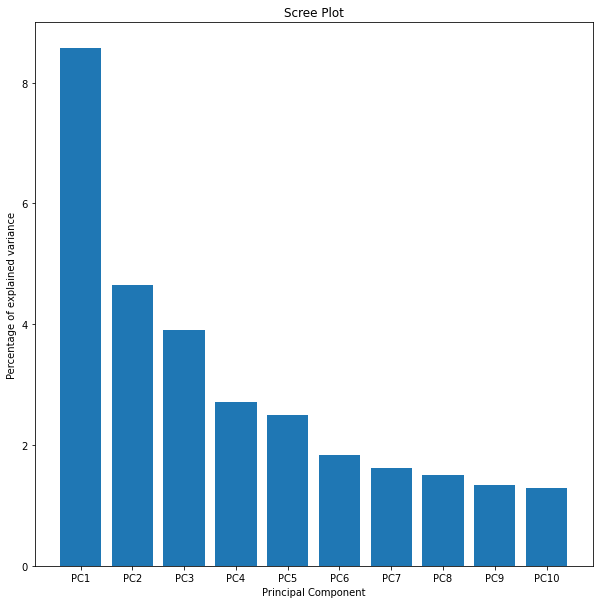

In [138]:
from sklearn.preprocessing import StandardScaler
import numpy as np 
import matplotlib.pyplot as plt


# Standardizing the features
scaled_data = StandardScaler().fit_transform(df)
pca = PCA()
pca_data = pca.fit_transform(scaled_data)

# plot the percentage of variance explained by each of the selected components
per_variation = pca.explained_variance_ratio_ * 100
labels = ["PC" + str(num) for num in range(1, len(per_variation[:10]) + 1)]
cplt.bar(x = range(1, len(per_variation[:10]) + 1), 
        height=per_variation[:10], 
        tick_label = labels
)
plt.xlabel("Principal Component")
plt.ylabel("Percentage of explained variance")
plt.title("Scree Plot")
plt.show()

In [139]:
import seaborn as sns
import time

def print_runtime(fn):
    start_time = time.time()
    out = fn()
    print("Took %s seconds" % (time.time() - start_time))
    return out 
    

def visualize2d(xs, ys, dfs, titles, cs):
    f = plt.figure(figsize=(30,10))
    ax1 = f.add_subplot(1, 3, 1)
    ax2 = f.add_subplot(1, 3, 2)
    ax3 = f.add_subplot(1, 3, 3 )
    axs = [ax1, ax2, ax3]
    
    for i, ax in enumerate(axs):
        ax.title.set_text(titles[i])
        ax.scatter(
        x=xs[i], 
        y=ys[i],
        data=dfs[i],
        c=cs[i]
        )

In [140]:
pca = PCA(n_components = 2)
pca_data = print_runtime(lambda: pca.fit_transform(scaled_data))
pca_df = pd.DataFrame(data = pca_data, columns = ["PC1", "PC2"])

Took 0.44989609718322754 seconds


In [141]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2)
tsne_data = print_runtime(lambda: tsne.fit_transform(scaled_data))
tsne_df = pd.DataFrame(data = tsne_data, columns = ["TSNE1", "TSNE2"])

Took 6.109622955322266 seconds


In [142]:
import umap

umap_data = print_runtime(lambda: umap.UMAP().fit_transform(scaled_data))
umap_df = pd.DataFrame(data = umap_data, columns = ["UMAP1", "UMAP2"])

Took 16.483091354370117 seconds


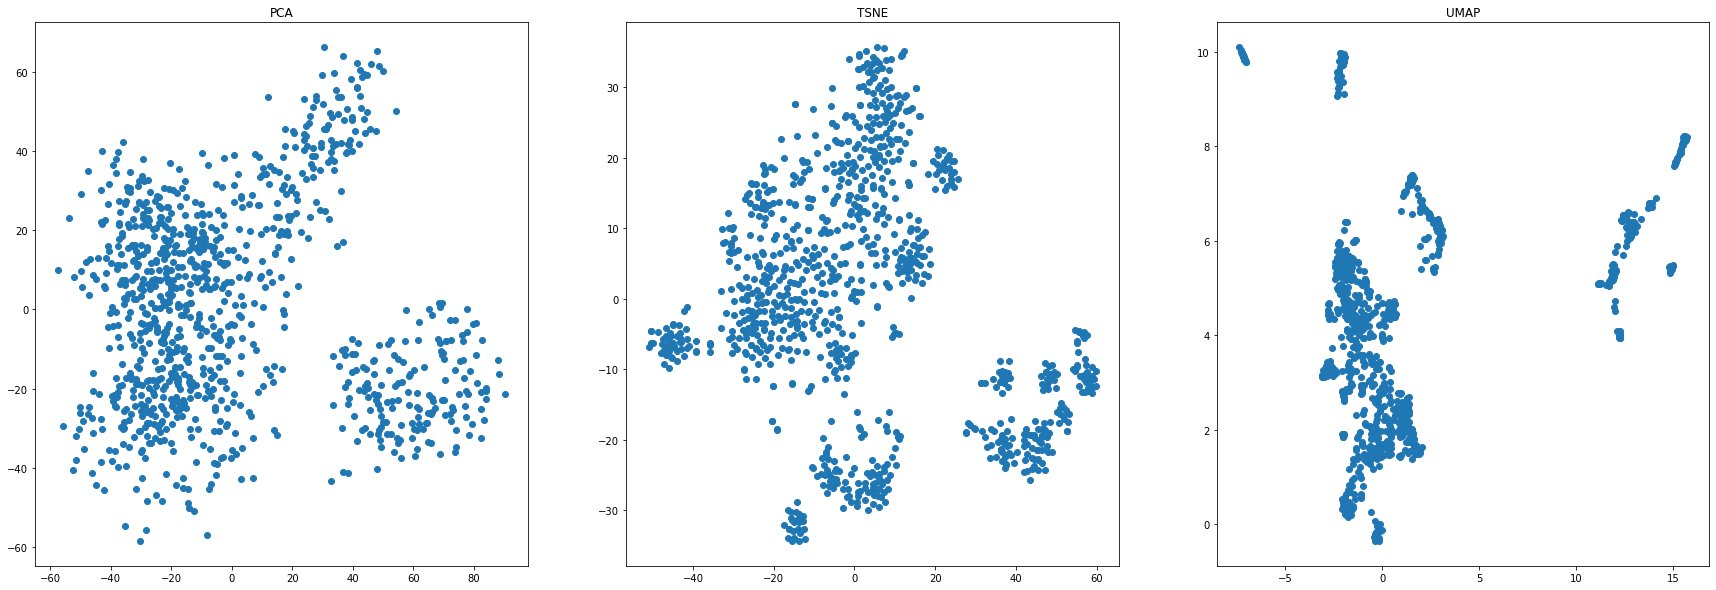

In [143]:
xs, ys = ["PC1", "TSNE1", "UMAP1"], ["PC2", "TSNE2", "UMAP2"] 
dfs = [pca_df, tsne_df, umap_df]
methods = ["PCA", "TSNE", "UMAP"]
visualize2d(xs, ys, dfs, methods, [None, None, None])

In [159]:
from sklearn.cluster import KMeans
import warnings
from sklearn.metrics import silhouette_score

# Ignore windows memory leak warning for kmeans
warnings.filterwarnings('ignore')

k_max = 20
k_range = range(1, k_max)
sse = []
silhouette_coefficients = []
for k in k_range:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(scaled_data)
    if k != 1:
        silhouette_coefficients.append(silhouette_score(scaled_data, kmeans.labels_))
    sse.append(kmeans.inertia_)

In [160]:
def silhouette_plot(n_clusters, silhouette_coefficients):
    plt.figure(figsize=(10,10))
    plt.plot(range(2, n_clusters), silhouette_coefficients)
    plt.xticks(range(2, n_clusters))
    plt.xlabel("Number of Clusters")
    plt.ylabel("Silhouette Coefficient")
    plt.title("Silhouette plot")

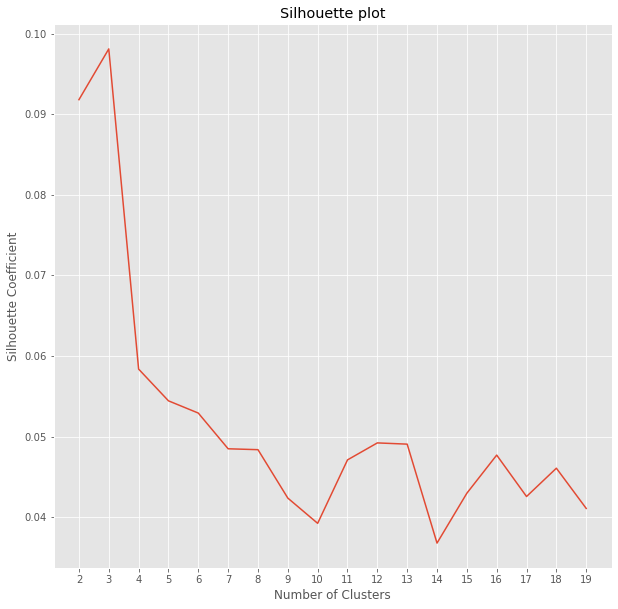

In [161]:
silhouette_plot(20, silhouette_coefficients)

<Figure size 720x720 with 0 Axes>

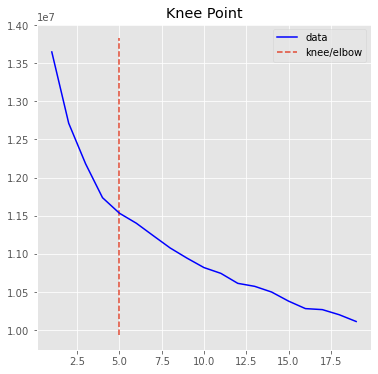

In [154]:
from kneed import KneeLocator

# draw the elbow plot
plt.figure(figsize=(10,10))
kl = KneeLocator(range(1, 20), sse, curve="convex", direction="decreasing")
kl.plot_knee()
plt.show()

Took 1.911848783493042 seconds


0.09809302584375687

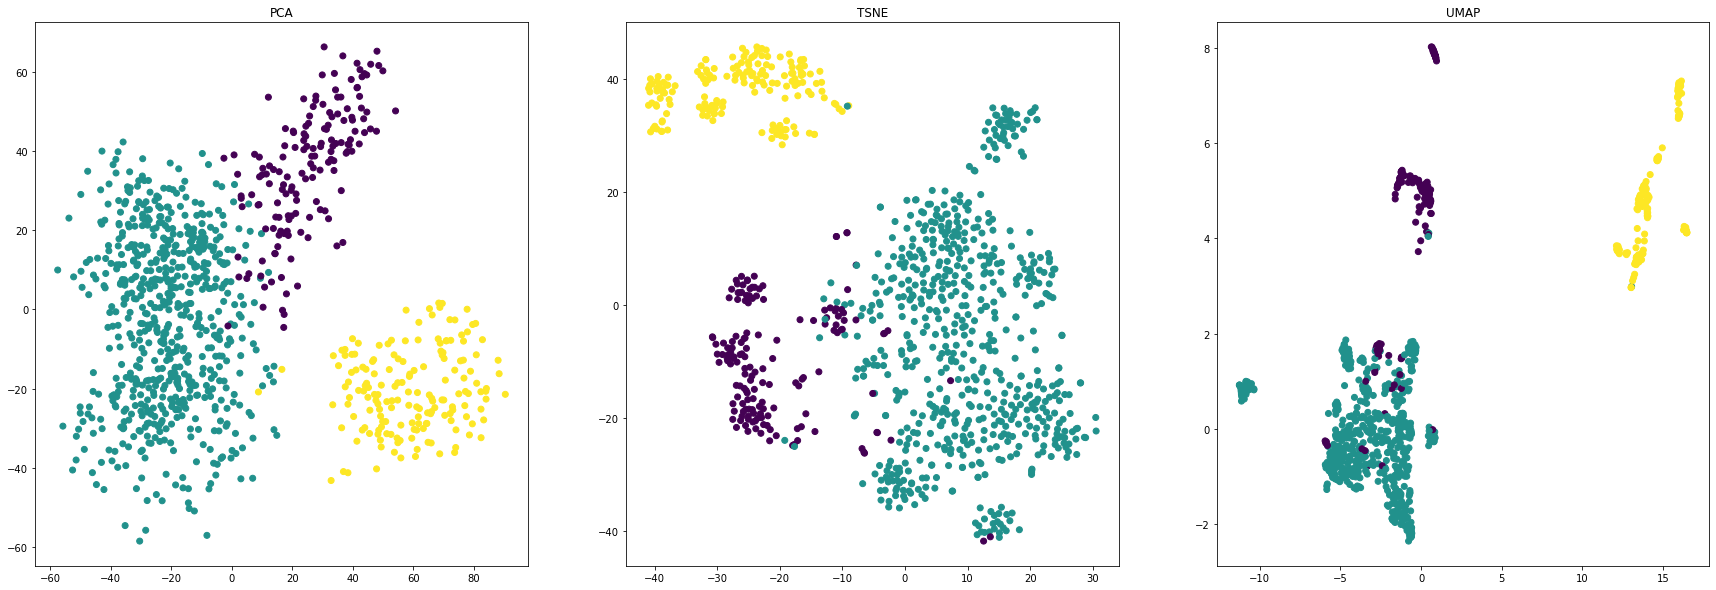

In [112]:
kmeans = KMeans(n_clusters=3, random_state=0)
y_predicted = print_runtime(lambda: kmeans.fit_predict(scaled_data))
for d in dfs:
    d["kmeans"] = y_predicted

visualize2d(xs, ys, dfs, titles=methods, cs=[d["kmeans"] for d in dfs])

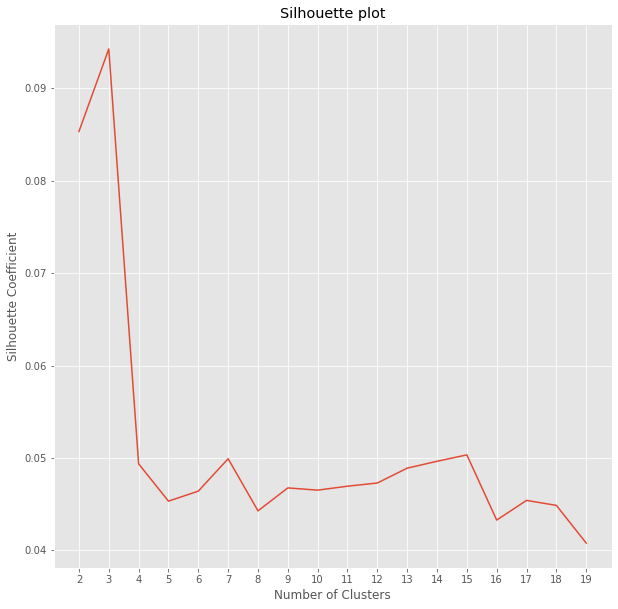

In [165]:
n_clusters = 20
cluster_range = range(2, n_clusters)

silhouette_coefficients = []
for n in cluster_range:
    agglomerative = AgglomerativeClustering(n_clusters=n)
    agglomerative.fit(scaled_data)
    silhouette_coefficients.append(silhouette_score(scaled_data, agglomerative.labels_))

silhouette_plot(20, silhouette_coefficients)

Took 6.9125871658325195 seconds


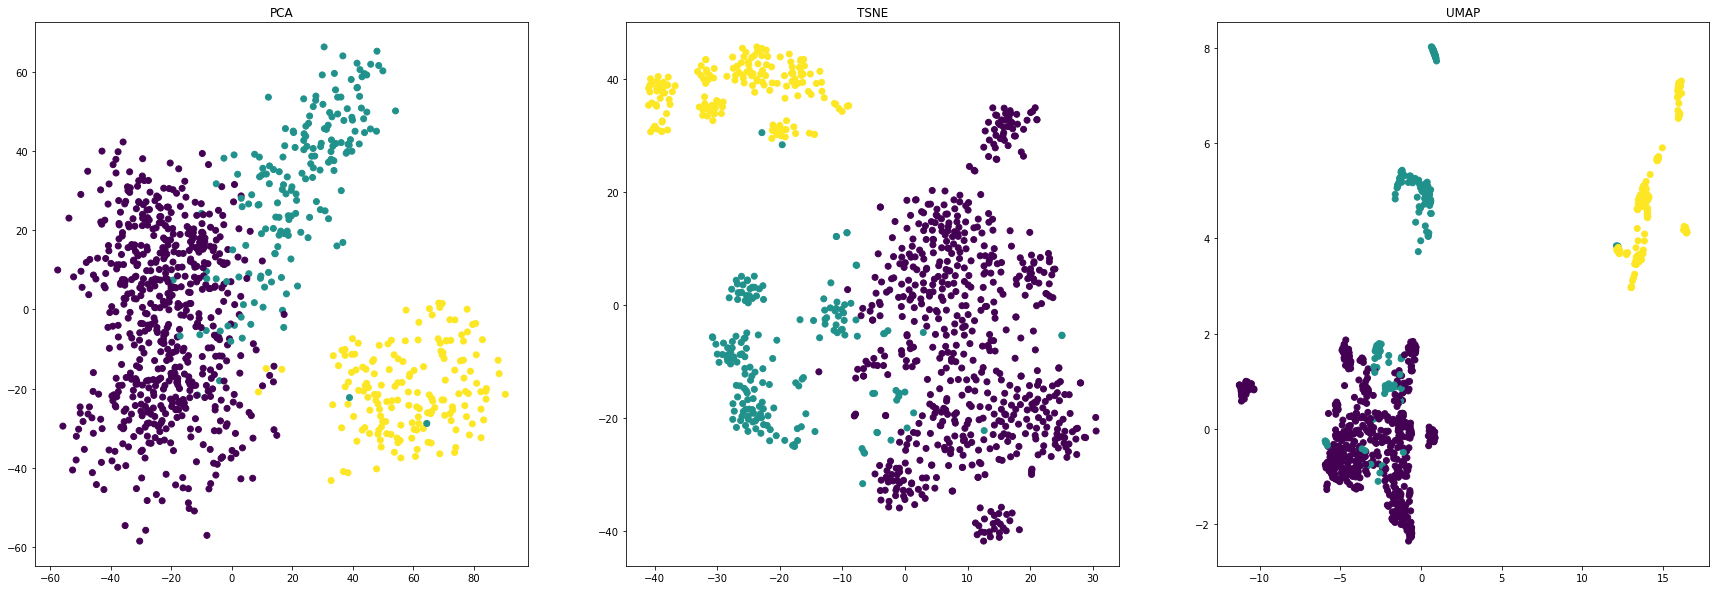

In [113]:
from sklearn.cluster import AgglomerativeClustering

agglomerative = AgglomerativeClustering(n_clusters=3)
y_predicted = print_runtime(lambda: agglomerative.fit_predict(scaled_data))
for d in dfs:
    d["agglomerative"] = y_predicted

visualize2d(xs, ys, dfs, titles=methods, cs=[d["agglomerative"] for d in dfs])    

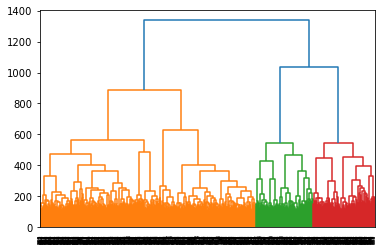

In [107]:
import scipy.cluster.hierarchy as sch
plt.figure(figsize=(10,10))
dendrogram = sch.dendrogram(sch.linkage(scaled_data, method="ward", metric="euclidean"))